# `appfig-training-curves`: training CE and Flights validation metrics over choice training

In [1]:
from pathlib import Path
import json
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

ASSET_NAME = "appfig-training-curves"
ASSET_DIR = Path.cwd()
PAPER_DIR = ASSET_DIR.parent
SRC_DIR = PAPER_DIR / "src"
if not (SRC_DIR / "microdata_analysis.py").is_file():
    raise FileNotFoundError(f"Open this notebook from assets/; {SRC_DIR} has no microdata_analysis.py")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import microdata_analysis as ma

print(f"Outputs go to {ASSET_DIR / ASSET_NAME}.*")

Outputs go to /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/appfig-training-curves.*


## Run design

In [2]:
RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
TRAINED_SLUGS = ("row2b_wu_ce_oracle", "row3_berke_ce_only", "row5_full_berke_wu_ce_oracle")
SELECTION_VALIDATOR = "kriner2026"

# Logs of every trained run, keyed by (model, regime)
step_logs = {}
val_logs = {}
run_summaries = {}
for model_slug in MODELS:
    for regime_slug in TRAINED_SLUGS:
        run_dir = ma.find_run_dir(RUN_ROOTS, model_slug, regime_slug)
        run_record = json.loads((run_dir / "run.json").read_text(encoding="utf-8"))
        if run_record["status"] != "finished":
            raise ValueError(f"{run_dir} status is {run_record['status']!r}, expected 'finished'")
        if run_record["identity"]["best_metric"] != f"{SELECTION_VALIDATOR}/beta_mse":
            raise ValueError(f"{run_dir}: checkpoint not selected on {SELECTION_VALIDATOR}/beta_mse")
        step_df = pd.read_csv(run_dir / "steps.csv")
        val_df = pd.read_csv(run_dir / "val_history.csv")
        summary = run_record["summary"]
        if not step_df["step"].is_unique or not val_df["step"].is_unique:
            raise ValueError(f"{run_dir}: repeated steps in steps.csv or val_history.csv")
        if len(step_df) != summary["total_steps"]:
            raise ValueError(f"{run_dir}: steps.csv has {len(step_df)} rows, run.json says {summary['total_steps']} steps")
        if summary["best_step"] not in set(val_df["step"]):
            raise ValueError(f"{run_dir}: selected step {summary['best_step']} has no validation row")
        step_logs[(model_slug, regime_slug)] = step_df
        val_logs[(model_slug, regime_slug)] = val_df
        run_summaries[(model_slug, regime_slug)] = summary
print(f"Loaded logs of {len(step_logs)} finished runs")

Loaded logs of 9 finished runs


## Labels and formatting (edit wording here)

In [9]:
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}

# Legend order follows this dict.
REGIME_LABELS = {
    "row2b_wu_ce_oracle": "Electricity",
    "row3_berke_ce_only": "Drones",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
REGIME_COLORS = {
    "row2b_wu_ce_oracle": "#2E8B78",
    "row3_berke_ce_only": "#6F5091",
    "row5_full_berke_wu_ce_oracle": "#1B365D",
}

# Panel rows, top to bottom: (log, column, scale, y label). "steps" rows are smoothed over SMOOTH_EPOCHS.
PANEL_ROWS = (
    ("steps", "ce_loss", 1.0, "Training CE"),
    ("val", f"{SELECTION_VALIDATOR}/kl_loss", 1.0, "Validation CE"),
    ("val", f"{SELECTION_VALIDATOR}/beta_mse", 1000.0, "Validation " + r"$\mathrm{MSE}_\beta\ (\times 10^3)$"),
)
# The selected checkpoint is marked on this panel row.
SELECTION_ROW_INDEX = 2
# Moving-average window of the per-step training CE, as a fraction of one epoch
SMOOTH_EPOCHS = 0.1

X_LABEL = "Epoch"
X_TICKS = (0, 1, 2, 3)
SELECTED_LABEL = "Selected checkpoint"

TEXT_COLOR = "#2B2B2B"
GRID_COLOR = "#D4D2CC"

PANEL_TITLE_SIZE = 11
LEGEND_SIZE = 9.0
LINE_WIDTH = 1.4
SELECTED_DOT_SIZE = 45

## Draw

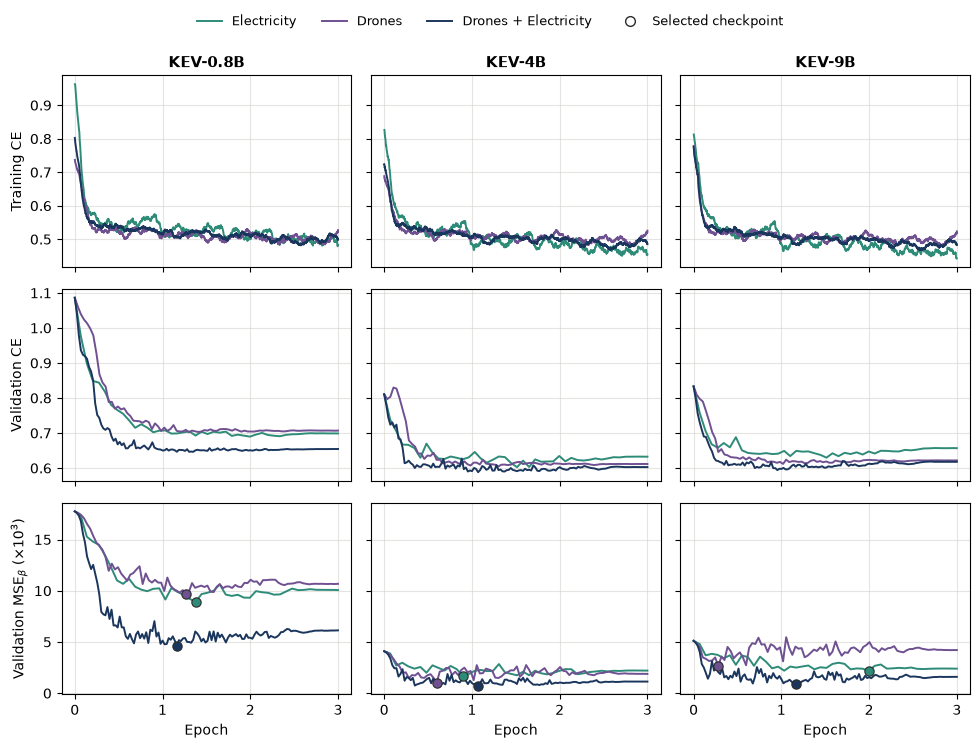

In [10]:
fig, axes = plt.subplots(
    len(PANEL_ROWS),
    len(MODELS),
    figsize=(3.3 * len(MODELS), 2.3 * len(PANEL_ROWS) + 0.6),
    sharex=True,
    sharey="row",
    squeeze=False,
)

for column_index, model_slug in enumerate(MODELS):
    for regime_slug, regime_label in REGIME_LABELS.items():
        summary = run_summaries[(model_slug, regime_slug)]
        steps_per_epoch = summary["steps_per_epoch"]
        color = REGIME_COLORS[regime_slug]
        for row_index, (log_name, column, scale, _) in enumerate(PANEL_ROWS):
            ax = axes[row_index, column_index]
            if log_name == "steps":
                log_df = step_logs[(model_slug, regime_slug)]
                window = round(SMOOTH_EPOCHS * steps_per_epoch)
                values = log_df[column].rolling(window, center=True, min_periods=1).mean()
            elif log_name == "val":
                log_df = val_logs[(model_slug, regime_slug)]
                values = log_df[column]
            else:
                raise ValueError(f"Unknown log {log_name!r}")
            if values.isna().any():
                raise ValueError(f"{model_slug}/{regime_slug}: missing {column} values")
            epochs = log_df["step"] / steps_per_epoch
            ax.plot(epochs, values * scale, color=color, linewidth=LINE_WIDTH, label=regime_label)
            if row_index == SELECTION_ROW_INDEX:
                best_row = log_df[log_df["step"] == summary["best_step"]].iloc[0]
                ax.scatter(
                    best_row["step"] / steps_per_epoch,
                    best_row[column] * scale,
                    s=SELECTED_DOT_SIZE,
                    color=color,
                    edgecolors=TEXT_COLOR,
                    linewidths=0.8,
                    zorder=3,
                )

for column_index, model_slug in enumerate(MODELS):
    axes[0, column_index].set_title(MODEL_LABELS[model_slug], fontsize=PANEL_TITLE_SIZE, fontweight="bold")
    axes[-1, column_index].set_xlabel(X_LABEL)
    axes[-1, column_index].set_xticks(X_TICKS)
for row_index, (_, _, _, y_label) in enumerate(PANEL_ROWS):
    axes[row_index, 0].set_ylabel(y_label)
for ax in axes.flat:
    ax.grid(color=GRID_COLOR, alpha=0.6)

handles, labels = axes[0, 0].get_legend_handles_labels()
selected_handle = plt.Line2D([], [], marker="o", linestyle="", markersize=7, markerfacecolor="white", markeredgecolor=TEXT_COLOR)
handles.append(selected_handle)
labels.append(SELECTED_LABEL)
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=len(labels), fontsize=LEGEND_SIZE, frameon=False)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))

## Save `appfig-training-curves.png` and `.pdf` (the manuscript points here)

In [11]:
for extension in ("png", "pdf"):
    figure_path = ASSET_DIR / f"{ASSET_NAME}.{extension}"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    print(f"Saved {figure_path}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/appfig-training-curves.png
Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/appfig-training-curves.pdf
